In [1]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pickle


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom_rs as bom
from models import hgm_rs as hgm

In [21]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm_rs' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm_rs.py'>

In [2]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [23]:
artificial = True
gcamp = True
gfp = True

In [3]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# file_ids = [7]

In [4]:
filenames = list()
boms_spn = list()
hgms_spn = list()

path = os.path.join(read_utils.get_data_path(), 'brain')

for file_id in file_ids:
	filename = read_utils.get_filename(read_utils.get_filepath(path, file_id))
	filenames.append(filename)

	load_path = f'../../out/predictions/{filename}/bom_rs/validation'
	bom_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	boms_spn.append(bom_spn)

	load_path = f'../../out/predictions/{filename}/hgm_rs/validation'
	hgm_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	hgms_spn.append(hgm_spn)

In [5]:
neuron_scores = assemble(boms_spn, hgms_spn)

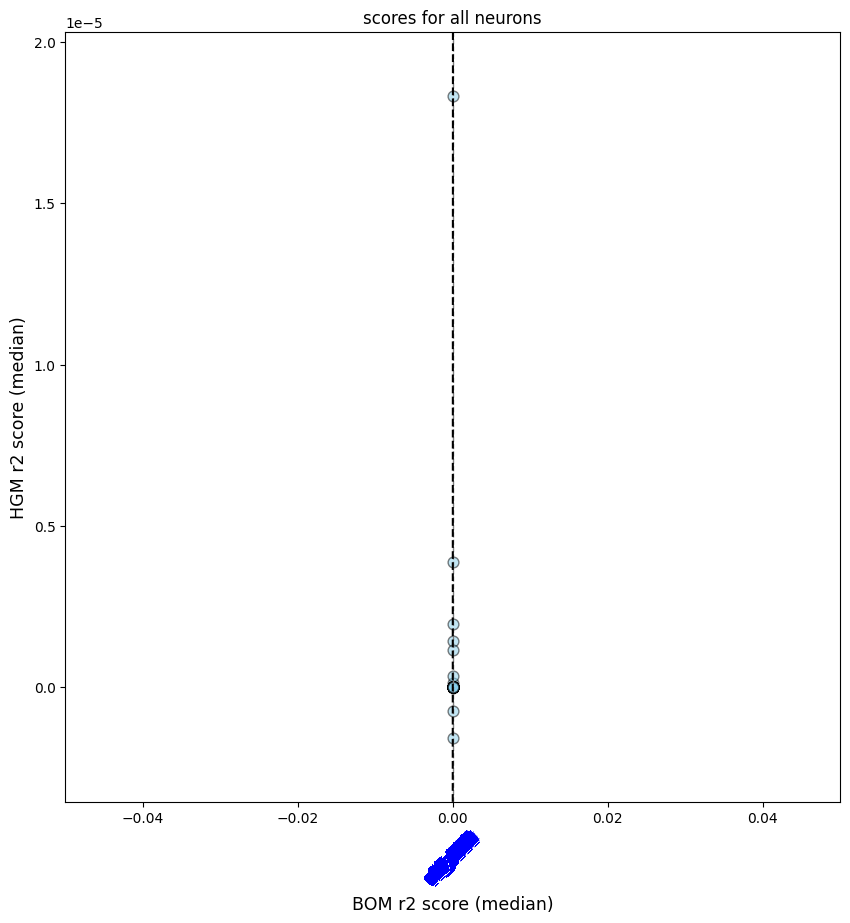

In [11]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=False
)

In [7]:
relevant_hgm_n = {key: value for key, value in neuron_scores.items() if 0 < value[0] < value[1]}

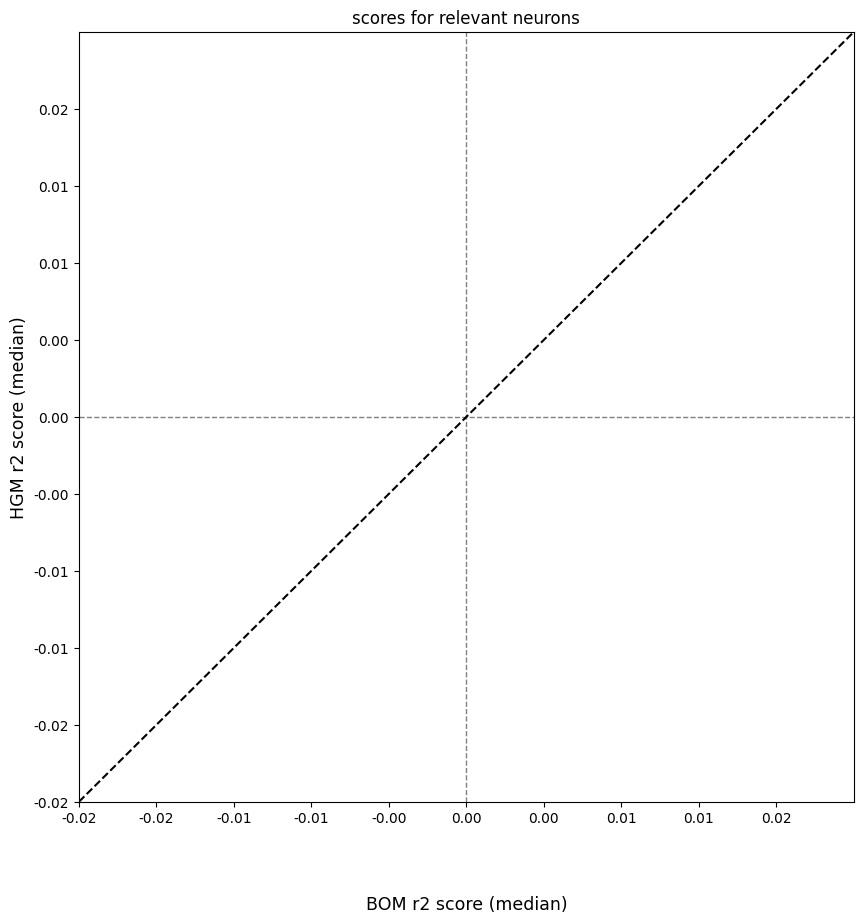

In [8]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='scores for relevant neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False
)

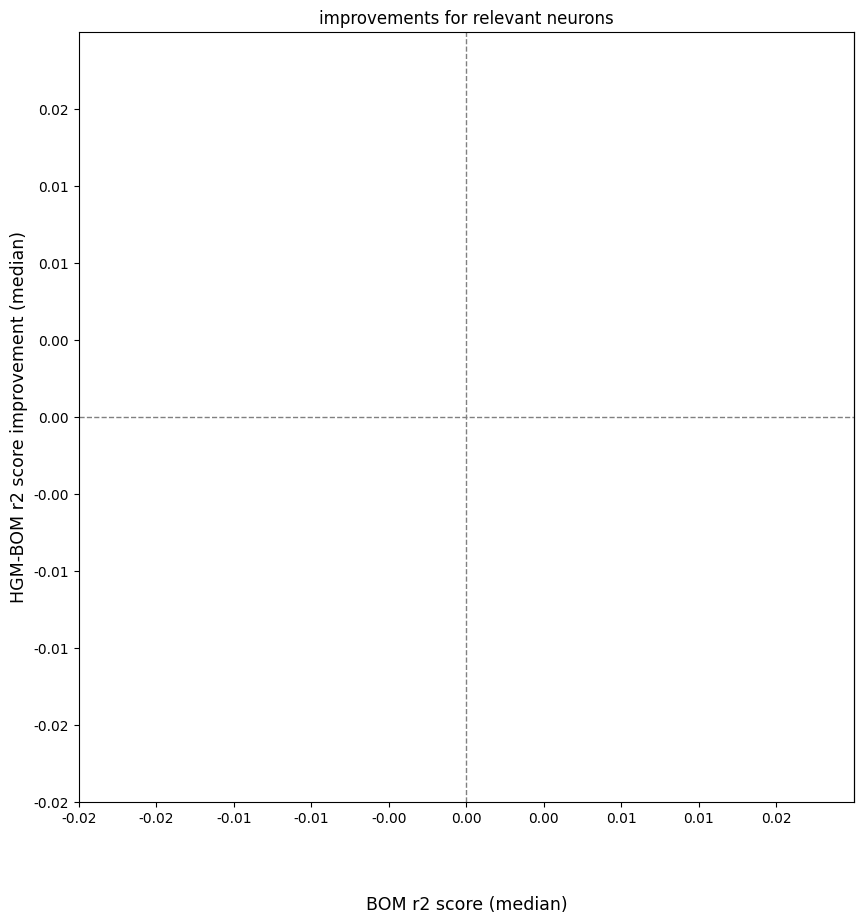

In [9]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='improvements for relevant neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False
)

In [10]:
relevant_hgmimpr_n_keys = list([val[0] for val in reversed(sorted(relevant_hgm_n.items(), key=lambda x: np.median(x[1][1] - x[1][0])))])[:5]
print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in list(reversed(sorted(relevant_hgm_n.items(), key=lambda x: np.median(x[1][1] - x[1][0]))))[:5]]))

# residual subspace